# Statistical Analysis of U.S. Murder Rates

This analysis evaluates the 2017 U.S. murder rates across different states to understand how extreme observations (outliers) influence key statistical summary metrics like the mean, standard deviation, and median.

### 1. Removing Washington D.C. as a Case Study
In statistics, mixing distinct populations can distort the analysis. Washington D.C. (`DC`) is a dense federal district and city, not a state. Its crime dynamics are fundamentally different from whole states, resulting in a much higher murder rate ($24.2$ per 100,000). Removing it allows us to analyze typical statewide distributions.

### 2. Basic Statistical Summary (Part a)
* **The Mean ($Μ$ or $\bar{x}$):** Represents the arithmetic average. It is computed as:
  $$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$
  It serves as the balance point of the dataset.
* **The Standard Deviation ($s$):** Measures the spread or variation of the data points from the mean:
  $$s = \sqrt{\frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}}$$
  A lower standard deviation indicates that the states' murder rates are closely clustered around the average, while a larger value indicates wider disparities.

### 3. The Five-Number Summary & Box Plot (Part b)
To describe the distribution without relying solely on the mean, we use robust rank-based metrics:
1. **Minimum:** The lowest recorded state rate.
2. **Lower Quartile ($Q_1$ or 25th percentile):** The rate below which 25% of states lie.
3. **Median ($Q_2$ or 50th percentile):** The exact middle value of the sorted data.
4. **Upper Quartile ($Q_3$ or 75th percentile):** The rate below which 75% of states lie.
5. **Maximum:** The highest recorded state rate.

* **Box Plot:** A standard box plot visualizes these 5 numbers. The central box spans from $Q_1$ to $Q_3$, containing the middle 50% of the data. The line inside the box represents the median. Any point beyond the "whiskers" (typically $1.5 \times \text{IQR}$ from the quartiles, where $\text{IQR} = Q_3 - Q_1$) is highlighted as a potential statistical outlier.



  state  murder
0    AK     8.4
1    AL     8.3
2    AR     8.6
3    AZ     5.9
4    CA     4.6
(a) Mean Murder Rate: 4.87, Std Dev: 2.59

(b) Five-Number Summary:
min     1.000
25%     2.625
50%     4.850
75%     6.175
max    12.400
Name: murder, dtype: float64


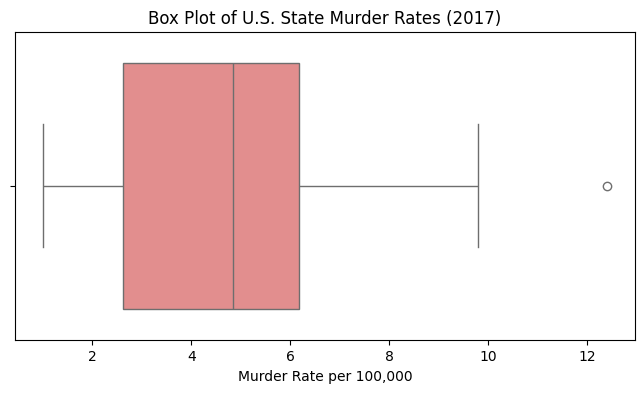


(c) Comparison with D.C. included:
Mean without D.C.: 4.87 | Mean with D.C.: 5.25
Median without D.C.: 4.85 | Median with D.C.: 5.00


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url_murder = "http://stat4ds.rwth-aachen.de/data/Murder.dat"
df_murder = pd.read_csv(url_murder, sep=r'\s+')

print(df_murder.head())

# (a) Mean and Standard Deviation (excluding D.C. if labeled as DC)
# Assuming columns include 'state' and 'murder'
df_no_dc = df_murder[df_murder['state'] != 'DC'] if 'state' in df_murder.columns else df_murder.iloc[:-1]

mean_m = df_no_dc['murder'].mean()
std_m = df_no_dc['murder'].std()
print(f"(a) Mean Murder Rate: {mean_m:.2f}, Std Dev: {std_m:.2f}")

# (b) Five-number summary and box plot
five_num = df_no_dc['murder'].describe(percentiles=[.25, .5, .75])
print("\n(b) Five-Number Summary:")
print(five_num[['min', '25%', '50%', '75%', 'max']])

plt.figure(figsize=(8, 4))
sns.boxplot(x=df_no_dc['murder'], color='lightcoral')
plt.title('Box Plot of U.S. State Murder Rates (2017)')
plt.xlabel('Murder Rate per 100,000')
plt.show()

# (c) Impact of including D.C.
df_with_dc = df_murder
print("\n(c) Comparison with D.C. included:")
print(f"Mean without D.C.: {df_no_dc['murder'].mean():.2f} | Mean with D.C.: {df_with_dc['murder'].mean():.2f}")
print(f"Median without D.C.: {df_no_dc['murder'].median():.2f} | Median with D.C.: {df_with_dc['murder'].median():.2f}")

### 4. Resistance/Robustness to Outliers (Part c)
One of the most important concepts in descriptive statistics is **resistance** to outliers:
* **Mean:** Since the formula sums *all* values, an extreme outlier like Washington D.C. pulls the mean significantly upward (from $4.87$ to $5.25$).
* **Median:** Since the median is purely rank-based (positional), it remains stable and resistant even when extreme values are added (shifting slightly from $4.85$ to $5.00$).